# Investigating river-level data across Scotland
**Emma Deyell, Gabriela Krawczyk & Saba Sitter**

# Setup

In [1]:
# Data libraries
import pandas as pd
import numpy as np


# Plotting libraries
import matplotlib.pyplot as plt
from matplotlib import image as mpimg
import seaborn as sns
import matplotlib.dates as mdates

# sklearn modules
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

# Set figure size
plt.rcParams.update({
    "figure.figsize": (7, 3),
    "font.size": 10,
    "figure.dpi": 150
})


In [2]:
# Load data  
df_avg = pd.read_csv("csv_files/avg_river_levels.csv")
df_min = pd.read_csv("csv_files/min_river_levels.csv")
df_max = pd.read_csv("csv_files/max_river_levels.csv")
df_locs = pd.read_csv("csv_files/monitoring_locations.csv")

# Introduction

This report investigates river water levels in Scotland using data from 392 river-level monitoring stations obtained from River Levels UK [1]. The datasets contain daily minimum, maximum and average water-level measurements for each monitoring station, collected from 05/10/2014 to 08/10/2026 (where observations are available). The report aims to address two main questions. Firstly, whether river monitoring stations can be grouped into distinct categories based on similarities in their water-level behaviour. Secondly, whether previous water-level measurements can be used to predict conditions in September, October, and November 2026 using linear regression.

To address the first question, features describing water-level variability and changes over time were extracted from the data. These features were standardised to allow comparisons between monitoring stations. Unsupervised learning techniques, including K-Means and hierarchical clustering, were explored to identify groups of stations exhibiting similar water-level behaviour.

The second question was investigated using supervised machine learning techniques, with the modelling approach and evaluation methods determined by the selected prediction task. WRITE MORE ABOUT QUESTION 2

Before applying these methods, exploratory data analysis and preprocessing were undertaken to investigate missing observations, unusual values and the geographical distribution of monitoring stations.

# Exploratory Data Analysis and Feature Engineering

## Exploratory Data Analysis


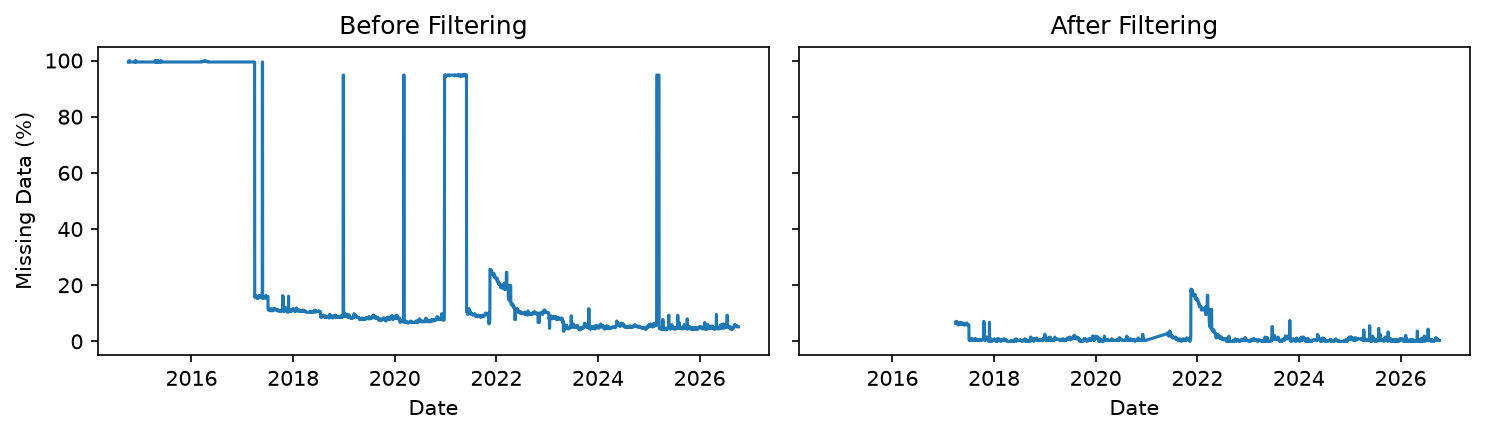

In [3]:
# Identify stations outside Scotland
stations_to_remove = df_locs.loc[
    df_locs["Station_Name"].str.strip().str.lower().isin(
        ["portrush", "bangor", "port erin"]),
    "Observation_ID"
].tolist()

# Clean and filter each dataset
def filter_data(df):
    df = df.replace([999999.999, -999999.999], np.nan)
    vals = df.iloc[:, 3:].copy()
    vals.columns = pd.to_datetime(vals.columns, dayfirst=True)
    vals.index = df["Observation_ID"]
    vals = vals.T.asfreq("D")
    spey = "inverness__spey-spey-dam__obs1"
    vals.loc[vals[spey] < -100, spey] = np.nan
    vals = vals.drop(columns=stations_to_remove, errors="ignore")

    # Remove incomplete dates and stations
    good = vals[vals.isna().mean(axis=1) <= 0.5]
    filtered = good.loc[:, good.isna().mean() <= 0.1]
    return vals, filtered

vals1, filtered_avg = filter_data(df_avg)
vals2, filtered_min = filter_data(df_min)
vals3, filtered_max = filter_data(df_max)

# Retain locations present in all three filtered datasets
common_stations = filtered_avg.columns.intersection(
    filtered_min.columns).intersection(filtered_max.columns)

df_locs_filtered = df_locs[
    df_locs["Observation_ID"].isin(common_stations)].copy()

# Percentage of missing observations per date
miss_unfil_row = vals1.isna().mean(axis=1) * 100
miss_fil_row = filtered_avg.isna().mean(axis=1) * 100

fig, ax = plt.subplots(1, 2, figsize=(10, 3),
                       sharex=True, sharey=True)

for a, data, title in zip(ax, [miss_unfil_row, miss_fil_row],
                          ["Before Filtering", "After Filtering"]):
    a.plot(data.index, data)
    a.set(xlabel="Date", title=title)

ax[0].set_ylabel("Missing Data (%)")
plt.tight_layout()
plt.show()


*Figure 1: Percentage of missing data over time before and after filtering.*

In [4]:
print(f"Missing before: {vals1.isna().values.mean():.2%}")
print(f"Missing after: {filtered_avg.isna().values.mean():.2%}")
print("Days removed:", len(vals1) - len(filtered_avg))
print("Stations removed:", len(df_locs) - len(df_locs_filtered))
print("Stations retained:", len(df_locs_filtered))

Missing before: 30.87%
Missing after: 1.33%
Days removed: 1094
Stations removed: 69
Stations retained: 323


Initial exploration of the datasets revealed that several observations had been replaced by the values 999999.999 or -999999.999, and there were also extremely negative values reported in several stations. These were treated as missing/invalid entries as per guidance from River Levels UK. $^3$ In addition, three monitoring stations (one in Portrush, one in Bangor, & one on the Isle of Man) were identified as being located outside Scotland by overlaying the stations on a map of the UK and were hence removed from the analysis.

After these initial adjustments, the extent of missing data was investigated. A substantial proportion of the observations were missing, particularly at the beginning of the time period. To reduce the impact of this, dates for which more than 50% of stations had missing observations were removed. Following this, stations with more than 10% missing observations across the remaining dates were also excluded. As shown in Figure 1, the proportion of missing observations decreased considerably following preprocessing. Following filtering, the overall percentage of missing observations decreased from 30.87% to 1.33%. This increase in data completeness came at the expense of 1094 days and 69 monitoring stations being removed from the data. 

The geographical distribution of monitoring stations was also examined before and after filtering to investigate the impact of preprocessing on station coverage. Because the absolute water level recorded at each monitoring station depends on its local reference level, direct comparison of water levels between stations is not generally possible. Therefore, feature engineering focused primarily on measures of variability and relative change rather than absolute level. Table 1 details the features created based on the river level data. 

## Feature Engineering 

In [13]:

# Align the three datasets by station and date
common_dates = filtered_avg.index.intersection(
    filtered_min.index).intersection(filtered_max.index)

avg = filtered_avg.loc[common_dates, common_stations].T
min_level = filtered_min.loc[common_dates, common_stations].T
max_level = filtered_max.loc[common_dates, common_stations].T

df_features = df_locs.set_index("Observation_ID").loc[common_stations].copy()

# Calculate daily range and consecutive daily changes
daily_range = max_level - min_level
daily_change = avg.T.sort_index().asfreq("D").diff().T

# Construct features
df_features["Mean_Daily_Range"] = daily_range.mean(axis=1)
df_features["Std_Daily_Range"] = daily_range.std(axis=1)
df_features["Mean_Absolute_Daily_Change"] = daily_change.abs().mean(axis=1)

# Calculate percentage of observations exceeding global thresholds
threshold_range = daily_range.stack().quantile(0.90)
threshold_rise = daily_change.stack().quantile(0.90)

df_features["Percent_Rise_Above_Threshold"] = (
    daily_change.gt(threshold_rise).sum(axis=1)
    / daily_change.notna().sum(axis=1) * 100)

df_features = df_features.reset_index()

| Feature UPDATE | Description UPDATE |
|---|---|
| Std_Level | Standard deviation of average river level |
| Mean_Daily_Range | Mean daily range |
| Std_Daily_Range | Standard deviation of daily range |
| 90th_Daily_Range | 90th percentile of daily range |
| Mean_Absolute_Daily_Change | Mean absolute change in water level between consecutive days |
| Std_Daily_Change | Standard deviation of daily changes |
| Percent_Range_Above_Threshold | Percentage of daily ranges exceeding the global 90th percentile |
| Percent_Rise_Above_Threshold | Percentage of daily changes exceeding the global 90th percentile of daily changes |

*Table 1: Features created from river-level data.*

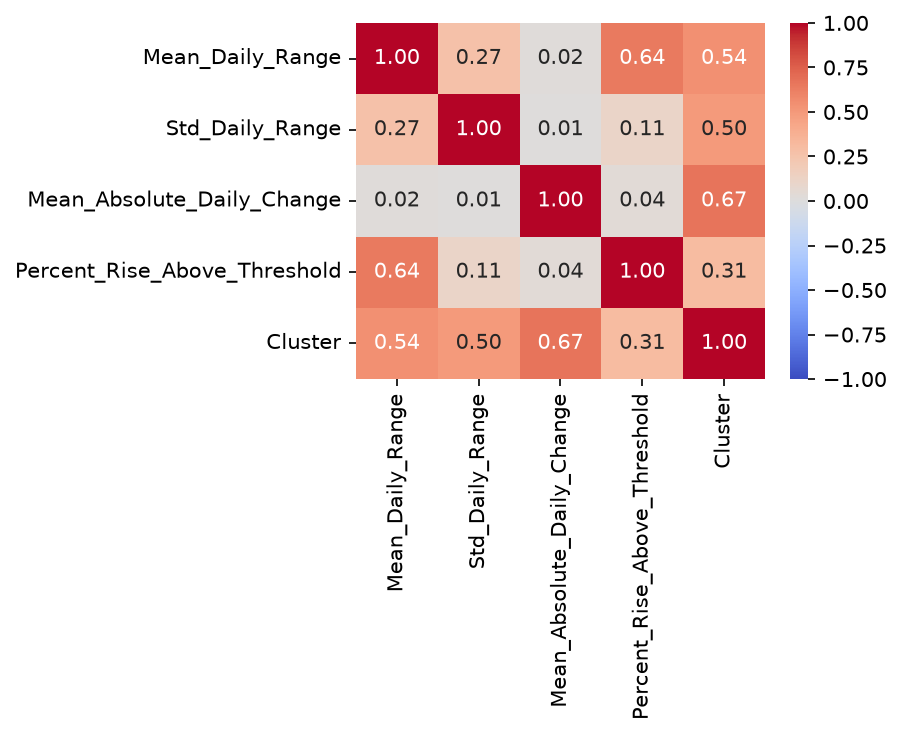

In [37]:
#Correlation matrix code 
df_visualise = df_features.drop(columns=[
    "Observation_ID", "County", "Station_Name",
    "Latitude", "Longitude"])

plt.figure(figsize = (6,5))
sns.heatmap(df_visualise.corr(), annot=True, cmap="coolwarm",
            fmt=".2f", vmin=-1, vmax=1)
plt.tight_layout()
plt.show()

*Figure 2: Correlation matrix of the engineered river-level features.*


The features as described in Table 1 were selected to capture different aspects of water-level behaviour, including overall variability, fluctuations within individual days, changes between consecutive days and the frequency of unusually large increases in water level. These characteristics were considered particularly relevant as stations may exhibit similar typical behaviour while responding differently to extreme weather events. Daily changes were calculated between consecutive calendar days to avoid treating changes across missing dates as single-day changes.

Relationships between the engineered features were investigated using a correlation matrix as displayed in Figure 2. A particularly strong correlation of [XX] was observed between [FEATURE] and [FEATURE]. This suggested that several of the engineered features captured similar aspects of water-level behaviour. Consequently, [JUSTIFY FINAL FEATURE SELECTION]. Consequently, [DISCUSS WHETHER ANY FEATURES WERE REMOVED OR PCA WAS USED TO ADDRESS THIS].

## Clustering

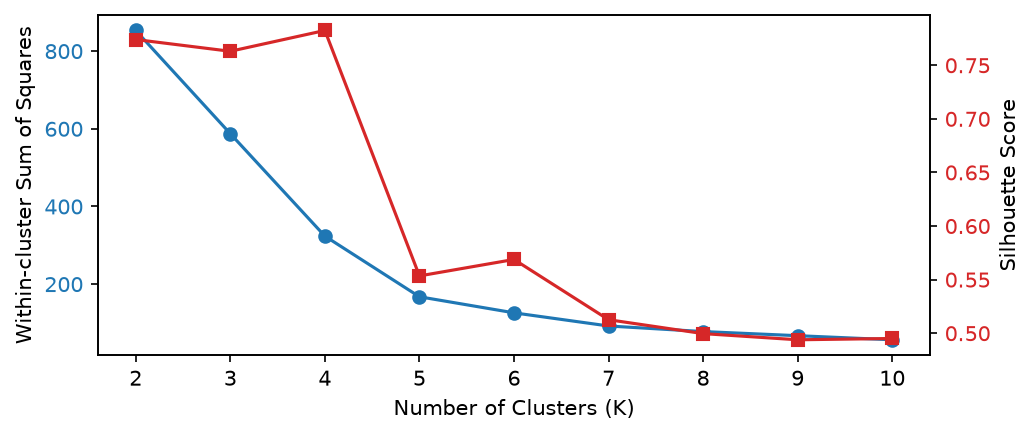

In [21]:
feature_cols = df_visualise.columns
df_scaled = StandardScaler().fit_transform(df_visualise) #Standardise 

#Silhouette plot
K_range = range(2, 11)
inertias, silhouette_scores = [], []

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(df_scaled)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(df_scaled, labels))

fig, ax1 = plt.subplots()
ax1.plot(K_range, inertias, "o-", color="tab:blue")
ax1.set(xlabel="Number of Clusters (K)",
        ylabel="Within-cluster Sum of Squares")

ax2 = ax1.twinx()
ax2.plot(K_range, silhouette_scores, "s-", color="tab:red")
ax2.set_ylabel("Silhouette Score")
ax1.tick_params(axis="y", labelcolor="tab:blue")
ax2.tick_params(axis="y", labelcolor="tab:red")

plt.tight_layout()
plt.show()



*Figure 3: Within-cluster variation and silhouette coefficients for different values of K.*

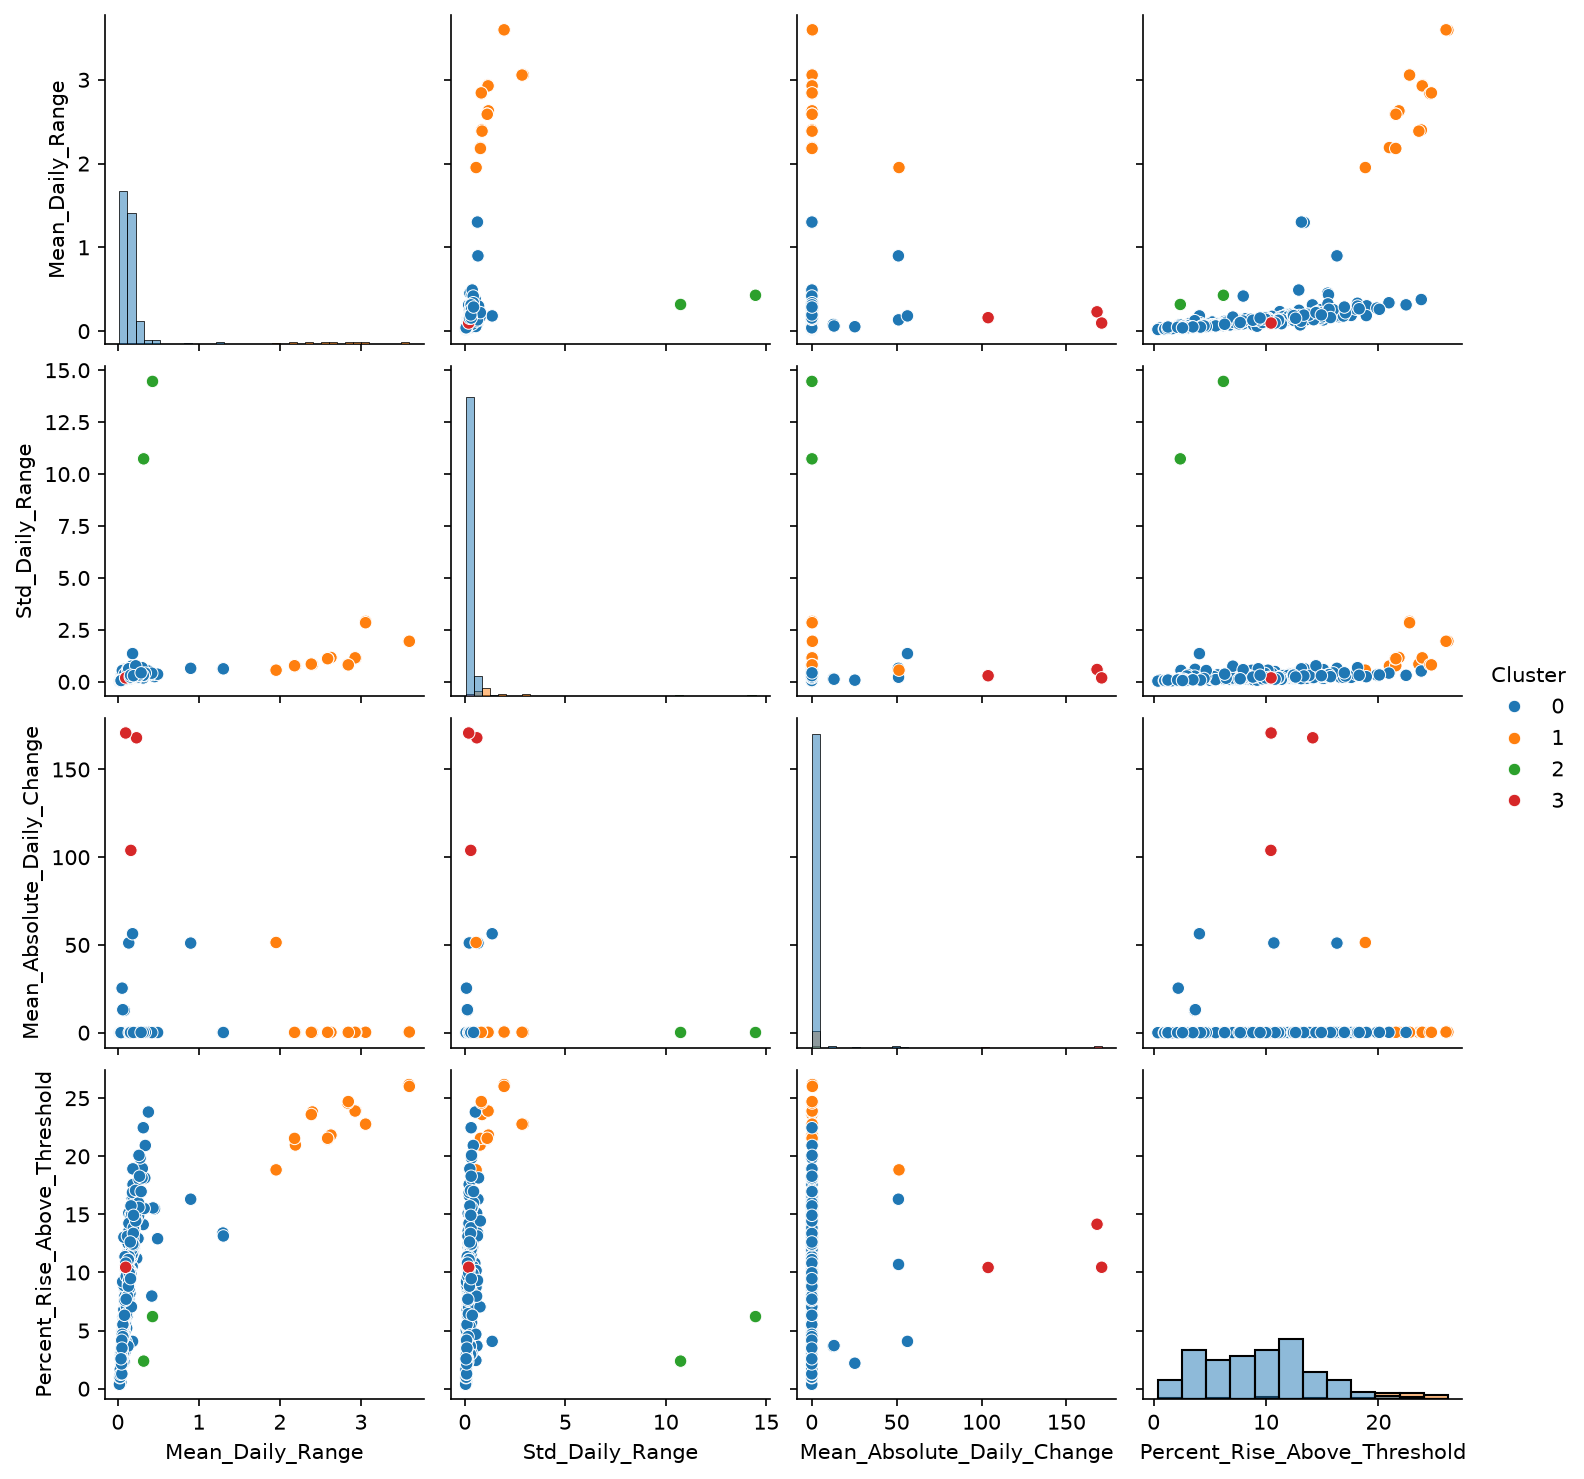

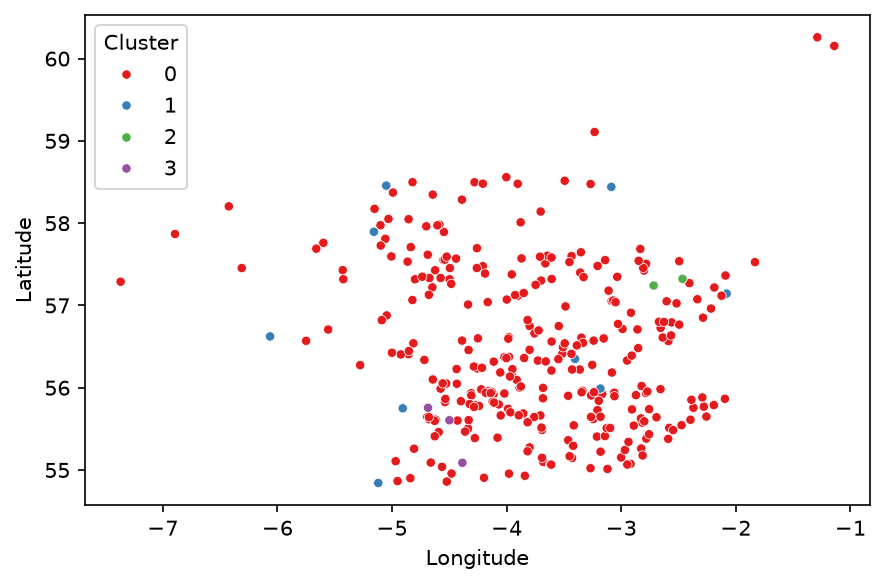

In [34]:
#Finding and assigning the clusters
K_final = 4  # Replace with final choice
kmeans = KMeans(n_clusters=K_final, random_state=42, n_init=10)
df_features["Cluster"] = kmeans.fit_predict(df_scaled)

#Visualise using pairplots 
df_visualise = df_features.drop(columns = ['Station_Name', 'Latitude', 'Longitude'])
sns.pairplot(df_visualise, hue = "Cluster", palette='tab10', diag_kind='hist')


#make this subplots with the geographical distribution
plt.figure(figsize = (6,4))
sns.scatterplot(data=df_features, x="Longitude", y="Latitude",
                hue="Cluster", palette="Set1", s=20)
plt.tight_layout()
plt.show()

*Figure 4: Pairplots demonstrating clustering relationships.*
*Figure 5: Visualisation of clusters and geographical distribution.*

In [35]:
cluster_summary = df_features.groupby("Cluster")[feature_cols].mean()
cluster_summary["Number of Stations"] = df_features.groupby("Cluster").size()

display(cluster_summary.T.round(3))

Cluster,0,1,2,3
Mean_Daily_Range,0.142,2.729,0.373,0.163
Std_Daily_Range,0.243,1.295,12.597,0.362
Mean_Absolute_Daily_Change,0.769,3.240,0.124,147.575
Percent_Rise_Above_Threshold,9.252,22.957,4.290,11.677
Number of Stations,301.000,17.000,2.000,3.000


*Table 3: Cluster characteristics.*


The features selected in the previous section were used as the basis for clustering the river monitoring stations according to similarities in their water-level behaviour. Due to differences in the scale and magnitude of the explanatory variables, standardisation was performed prior to clustering, such that each variable had a mean of zero and a standard deviation of one. This prevented variables with larger numerical values from disproportionately influencing the clustering results.

K-Means clustering was initially investigated due to its simplicity, computational efficiency and interpretability. The algorithm assigns observations to clusters by minimising the within-cluster sum of squared distances from their respective cluster centres.Hierarchical clustering was also considered as an alternative approach, as it does not require the number of clusters to be specified prior to constructing the cluster hierarchy. This provided an alternative means of investigating the underlying relationships between monitoring stations.

To investigate the optimal number of clusters for K-Means, the within-cluster variation and silhouette coefficients were calculated for different values of K. The within-cluster variation decreases as the number of clusters increases. However, increasing the number of clusters does not necessarily produce a more meaningful clustering solution. The elbow method was therefore used to identify a point beyond which additional clusters provided relatively little improvement. The silhouette coefficient was also used to assess how closely observations were associated with their assigned clusters relative to neighbouring clusters. Higher silhouette coefficients indicate greater cluster cohesion and separation.

As shown in Figure 4, the rate of decrease in within-cluster variation became less substantial beyond approximately K = 3. The highest silhouette coefficient was obtained for K = 4. However, the distribution of stations across clusters and the interpretability of the resulting groups were also considered when selecting the final clustering solution, and so K = 3 was chosen as it was also above the 90% threshold of the explained variance ratio.

To further investigate the characteristics of the resulting clusters, the average values of the explanatory variables within each cluster were calculated. The main distinguishing characteristics between the clusters were [FEATURES]. Monitoring stations within Cluster 1 were characterised by [XX], whilst those within Cluster 2 exhibited [XX].

The geographical distribution of the resulting clusters was investigated to determine whether similarities in water-level behaviour were associated with geographical location. As shown in Figure 5, [DISCUSS GEOGRAPHICAL PATTERNS AND POTENTIAL EXPLANATIONS].

## Data Preparation for Supervised Learning

To evaluate the predictive performance of the supervised learning model, the dataset was divided into training and testing sets. Due to the time-dependent nature of river-level observations, the data were split chronologically rather than randomly. This prevented future observations from being used to predict historical water levels and make the forecasting more realistic.

The training dataset consisted of observations between 31/03/2017 and 31/08/2026. The forecasting period extended from 01/09/2026 to 30/11/2026, however, as recorded observations were only available until 08/10/2026, model performance could only be evaluated until then. 

Further feature engineering was undertaken to construct explanatory variables relevant to water-level prediction.

[EDIT TO ADD FEATURES AND JUSTIFICAITON ]

A sklearn pipeline was used to incorporate the necessary preprocessing steps into the model-fitting process, ensuring that any preprocessing requiring fitted parameters was based solely on the training data. The implementation of this pipeline is detailed in the Model Fitting and Tuning section.


Baseline MAE: 0.14695148609517564
Baseline RMSE: 0.2230487288453925
Observations evaluated: 12202


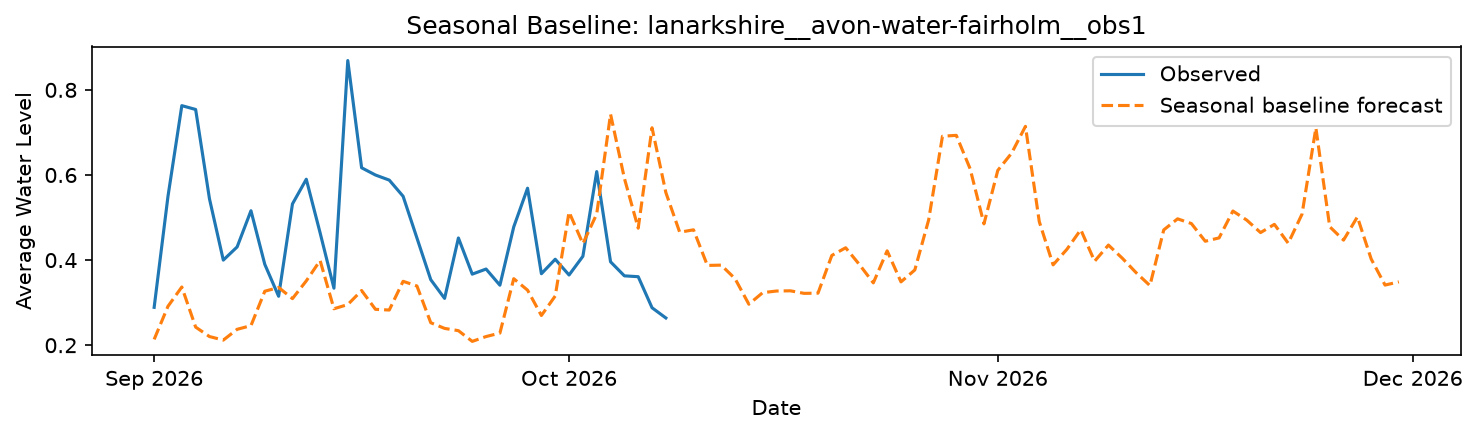

In [38]:
# Training data before September 2026
train_avg = filtered_avg.asfreq("D").loc[:"2026-08-31"]

# Forecast September-November 2026
forecast_dates = pd.date_range("2026-09-01", "2026-11-30")
baseline_forecast = pd.DataFrame(index=forecast_dates, columns=train_avg.columns, dtype=float)

# Equivalent dates from the previous six years
for date in forecast_dates:
    previous_dates = [date - pd.DateOffset(years=i) for i in range(1, 7)]
    baseline_forecast.loc[date] = train_avg.reindex(previous_dates).mean().values

# Evaluate predictions where observations are available
actual = filtered_avg.reindex(forecast_dates)
errors = actual - baseline_forecast

baseline_mae = errors.abs().stack().mean()
baseline_rmse = np.sqrt(errors.pow(2).stack().mean())

print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)
print("Observations evaluated:", errors.notna().sum().sum())

# Plot predictions for a station
variation = baseline_forecast.std().dropna()
station = (variation - variation.median()).abs().idxmin()

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(actual.index, actual[station], label="Observed")
ax.plot(baseline_forecast.index, baseline_forecast[station], "--", label="Seasonal baseline forecast")
ax.set(xlabel="Date", ylabel="Average Water Level", title=f"Seasonal Baseline: {station}")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend()
plt.tight_layout()
plt.show()

*Figure 6: Baseline model accuracy for one station.*

# Model Fitting and Tuning

## Baseline Model

A seasonal baseline model was used to forecast daily average river water levels between September and November 2026. The approach was adapted from the equivalent-date forecasting method described in the Skforecast documentation $^2$.

For each forecasted date, the model calculated the mean water level recorded on the same day of the year over the previous six years, and used this to forecast the water level. This was performed independently for each monitoring station, producing forecasts for 91 days.

This method was selected because it provides a simple and interpretable baseline for evaluating more complex forecasting models. It allows predicted water levels to vary throughout the forecasting period according to historical seasonal behaviour, unlike a persistence model, which was also considered as a baseline. 

Model accuracy was assessed using mean absolute error (MAE) and root mean squared error (RMSE) for test dates where observations were available. Across 12,202 observations, the baseline had an MAE of 0.147 and an RMSE of 0.223. Figure 6 shows the seasonal baseline forecast for one monitoring station. The model captures variation in water level throughout the forecasting period, though differences are apparent, especially in September when water levels are underestimated. 

These results suggest that the seasonal baseline provides a reasonable benchmark for comparison with the final regression model, although it cannot account for sudden changes in water levels caused by unusual weather conditions.

# Interpretation, Discussion & Conclusions

The clustering analysis identified [XX] distinct groups of river monitoring stations across Scotland based on similarities in their water-level behaviour. The main distinguishing characteristics between these groups were [FEATURES].

The results of PCA suggested that two important aspects of river-level behaviour were the extent of general water-level variability and the magnitude and frequency of extreme fluctuations. The geographical distribution of the clusters also revealed [GEOGRAPHICAL FINDINGS].

One limitation of the analysis was the substantial proportion of missing observations in the original datasets. Although preprocessing reduced the percentage of missing observations from 30.61% to 1.33% in the average water-level dataset, approximately 25% of the original dates were removed. Consequently, the retained data may not be fully representative of river-level behaviour across the original time period.

Additionally, the engineered features were calculated across the retained time period, rather than accounting explicitly for seasonal variations in river-level behaviour. Monitoring stations exhibiting similar overall behaviour may behave differently at different times of the year.

The clustering results were also dependent on the choice of explanatory variables and clustering method. Further investigation into alternative feature sets and the stability of the resulting clusters could improve confidence in the findings.

This project investigated the application of supervised and unsupervised machine learning techniques to river-level monitoring data across Scotland.

The clustering analysis found that [MAIN CLUSTERING FINDINGS], whilst the supervised learning analysis demonstrated that [MAIN PREDICTION FINDINGS].

Together, these approaches demonstrate the potential for machine learning to improve understanding of river-level behaviour and support effective river management strategies across Scotland.

# Generative AI statement

*Include a statement on if and how generative AI was used in the project and report.*

# References

$^1$ https://riverlevels.uk/map
$^2$ https://skforecast.org/latest/user_guides/forecasting-baseline.html
$^3$ https://riverlevels.uk/pages/frequently-asked-questions


In [36]:
!jupyter nbconvert --to pdf project.ipynb --template=latex --template-file=compact.tex.j2

[NbConvertApp] Converting notebook project.ipynb to pdf
[NbConvertApp] Support files will be in project_files/
[NbConvertApp] Making directory ./project_files
[NbConvertApp] Writing 67590 bytes to notebook.tex
[NbConvertApp] Building PDF
[NbConvertApp] Running xelatex 3 times: ['xelatex', 'notebook.tex', '-quiet']
[NbConvertApp] Running bibtex 1 time: ['bibtex', 'notebook']
[NbConvertApp] WARNING | bibtex had problems, most likely because there were no citations
[NbConvertApp] PDF successfully created
[NbConvertApp] Writing 583540 bytes to project.pdf
